Before starting: import data file (files too large for github) to match structure below

```code
# Initial data File structure:
NSSP-Mini-project-1
    /data
        /T1   
            /T1w.nii.gz
        /fMRI
            /tFMRI_LANGUAGE_LR
                /tfMRI_LANGUAGE_LR_task_onsets.csv
                /tfMRI_LANGUAGE_LR.nii.gz
```

In [ ]:
import os          
import os.path as op                                             
import subprocess                          
import matplotlib.pyplot as plt             
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from nilearn import plotting # brain image plotting

### !!! EDIT THIS (if needed): !!!
data_dir = op.expanduser("~/Desktop/NSSP-Mini-project-1/data") 


out_dir = op.join(data_dir, "derivatives")
out_anatomical_dir = op.join(out_dir, "anat")
os.makedirs(out_dir, exist_ok=True)
os.makedirs(out_anatomical_dir, exist_ok=True)

t1_path = op.join(data_dir, "T1", "T1w.nii.gz") # original structural image
fig_dir = op.join(out_dir, "figures") # folder for the saved figures
os.makedirs(fig_dir, exist_ok=True)                 # create output folders (no error if they exist)
            

# FSL environment
## REQUIRE FSL download (https://fsl.fmrib.ox.ac.uk/fsl/docs/install/index.html)
fsldir = os.environ.get("FSLDIR", op.expanduser("~/fsl"))  # FSL install folder

# MNI152 templates
mni_head = op.join(fsldir, "data", "standard", "MNI152_T1_1mm.nii.gz")        # whole-head template
mni_brain = op.join(fsldir, "data", "standard", "MNI152_T1_1mm_brain.nii.gz")  # skull-stripped template


assert op.exists(t1_path), f"T1w image not found: {t1_path}"
assert op.exists(out_anatomical_dir), f"Output directory not found: {out_anatomical_dir}"
assert op.exists(fig_dir), f"Output directory not found: {fig_dir}"
assert op.exists(mni_head), f"MNI template not found: {mni_head}"
assert op.exists(mni_brain), f"MNI template not found: {mni_brain}"    

print("All good. T1w:", t1_path)


All good. T1w: /Users/matt/Desktop/NSSP-Mini-project-1/data/T1/T1w.nii.gz


## 1. skull-stripping with FSL BET

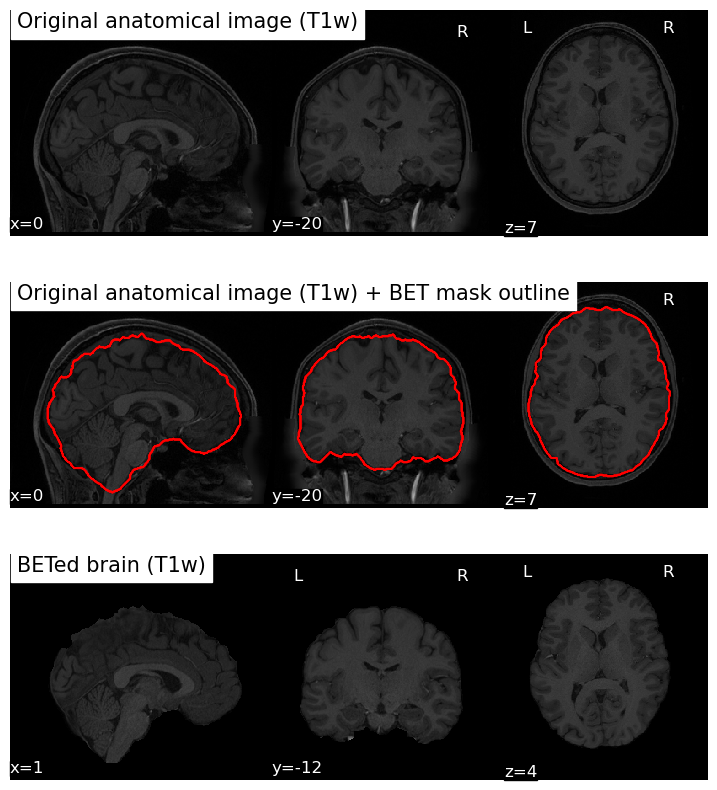

In [36]:
brain_prefix = op.join(out_anatomical_dir, "T1w_brain")         # BET output name (without extension)
brain = brain_prefix + ".nii.gz"                     # skull-stripped brain image
mask = brain_prefix + "_mask.nii.gz"                 # binary brain mask (created by bet -m)

# FSL BET: -R robust centre estimation, -f 0.3 threshold, -m save mask
subprocess.run(["bet", t1_path, brain_prefix, "-R", "-f", "0.3", "-m"], check=True)


fig, axs = plt.subplots(3, 1, figsize=(9, 10))       

# subplot 1: original T1w
plotting.plot_anat(t1_path, axes=axs[0], draw_cross=False, title="Original anatomical image (T1w)", colorbar=False)

# subplot 2: original T1w with the brain mask outline in red (to check the extraction quality)
ax = plotting.plot_anat(t1_path, axes=axs[1], draw_cross=False,
                          title="Original anatomical image (T1w) + BET mask outline", colorbar=False)
ax.add_contours(mask, colors="r", linewidths=1)  # draw the mask boundary

# subplot 3: betted brain
plotting.plot_anat(brain, axes=axs[2], draw_cross=False, title="BETed brain (T1w)", colorbar=False)

fig.savefig(op.join(fig_dir, "1_skull_stripping(BET).png"), dpi=1000)  
plt.show()                                          

## 2. tissue segmentation with FSL FAST

In [32]:
# Run FAST (takes a few minutes)
fast_prefix = op.join(out_anatomical_dir, "T1w_brain_fast")     
seg = fast_prefix + "_seg.nii.gz"       

# FAST: -t 1 = T1 image, -n 3 = three tissue classes
subprocess.run(["fast", "-t", "1", "-n", "3", "-o", fast_prefix, brain], check=True)

CompletedProcess(args=['fast', '-t', '1', '-n', '3', '-o', '/Users/matt/Desktop/NSSP-Mini-project-1/data/derivatives/anat/T1w_brain_fast', '/Users/matt/Desktop/NSSP-Mini-project-1/data/derivatives/anat/T1w_brain.nii.gz'], returncode=0)

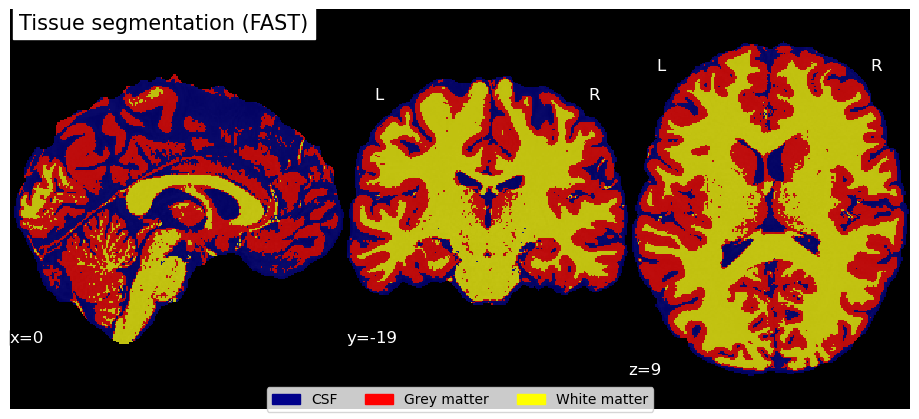

In [33]:
fig = plt.figure(figsize=(9, 4))

plotting.plot_roi(seg, bg_img=brain, vmin=1, vmax=3, cmap = ListedColormap(["darkblue", "red", "yellow"]),
                  alpha=0.7, colorbar=False, draw_cross=False, figure=fig,
                  title="Tissue segmentation (FAST)")



fig.legend(handles=[Patch(color="darkblue", label="CSF"), 
                    Patch(color="red", label="Grey matter"),
                    Patch(color="yellow", label="White matter")],
           loc="lower center", ncol=3)

fig.savefig(op.join(fig_dir, "2_segmentation.png"), dpi=1000)
plt.show()

## 3. registration to MNI space

In [ ]:
affine_mat = op.join(out_anatomical_dir, "T1_to_MNI_flirt.mat") # linear transformation matrix (from FLIRT)
brain_flirt = op.join(out_anatomical_dir, "T1w_brain_MNI_FLIRT.nii.gz") 

# FLIRT: linear registration
subprocess.run(["flirt", "-in", brain, "-ref", mni_brain, "-out", brain_flirt, "-omat", affine_mat], check=True)


# FNIRT: non-linear registration(takes a few minutes)
'''
brain_nl = op.join(out_anatomical_dir, "T1w_brain_MNI_nonlinear.nii.gz")  # brain after non-linear registration
subprocess.run(["fnirt", f"--in={t1_reori}", f"--ref={mni_head}", f"--aff={affine}",
                "--config=T1_2_MNI152_2mm", f"--cout={warp}"], check=True)
'''


'\nsubprocess.run(["fnirt", f"--in={t1_reori}", f"--ref={mni_head}", f"--aff={affine}",\n                "--config=T1_2_MNI152_2mm", f"--cout={warp}"], check=True)\n'

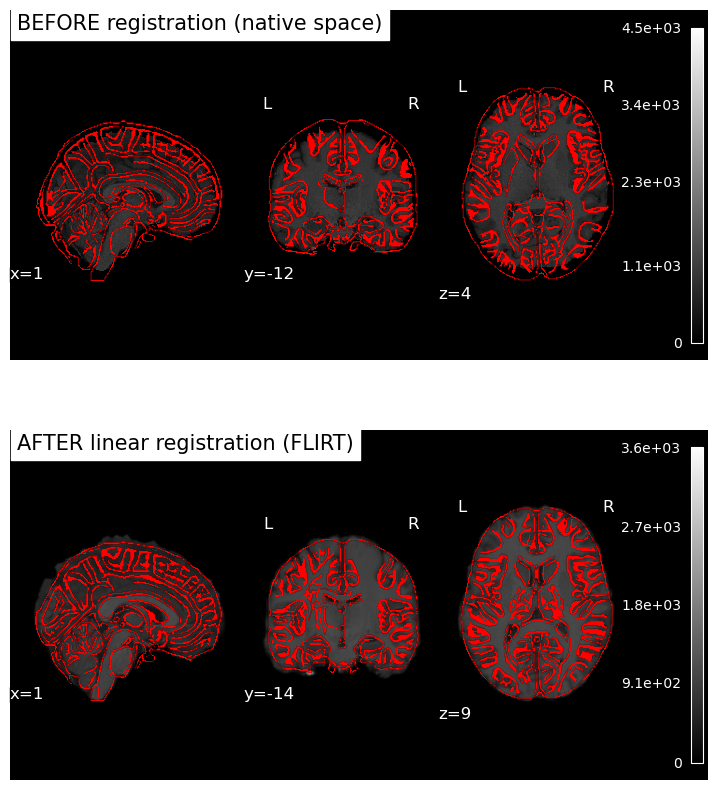

In [35]:
fig, axs = plt.subplots(2, 1, figsize=(9, 10))

d = plotting.plot_anat(brain, axes=axs[0], draw_cross=False,
                       title="BEFORE registration (native space)")
d.add_edges(mni_brain, color="r") # MNI edges on top

d = plotting.plot_anat(brain_flirt, axes=axs[1], draw_cross=False,
                       title="AFTER linear registration (FLIRT)")
d.add_edges(mni_brain, color="r")


fig.savefig(op.join(fig_dir, "3_registration_MNI.png"), dpi=1000)
plt.show()